> ## 0. Setup Paths
* Instalando com pip as principais bibliotecas.

In [2]:

%pip install pyyaml
%pip install Pillow
%pip install cycler
%pip install pytz
%pip install Pyarrow
%pip install pandas
%pip install openCv-python
%pip install gin-config
%pip install matplotlib
%pip install tensorflow==2.15

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


... (10 outputs left out)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached tensorflow-2.15.0-cp311-cp311-win_amd64.whl (2.1 kB)
  Using cached tensorflow_intel-2.15.0-cp311-cp311-win_amd64.whl (300.9 MB)
  Using cached ml_dtypes-0.2.0-cp311-cp311-win_amd64.whl (938 kB)
  Using cached tensorboard-2.15.2-py3-none-any.whl (5.5 MB)
  Using cached tensorflow_estimator-2.15.0-py2.py3-none-any.whl (441 kB)
  Using cached keras-2.15.0-py3-none-any.whl (1.7 MB)
  Using cached google_auth-2.29.0-py2.py3-none-any.whl (189 kB)
  Using cached google_auth_oauthlib-1.2.0-py2.py3-none-any.whl (24 kB)
  Using cached cachetools-5.3.3-py3-none-any.whl (9.3 kB)
  Using cached pyasn1_modules-0.4.0-py3-none-any.whl (181 kB)
  Using cached rsa-4.9-py3-none-any.whl (34 kB)
  Using cached requests_oauthlib-2.0.0-py2.py3-none-any.whl (24 kB)
  Using cached pyasn1-0.6.0-py2.py3-none-any.whl (85 kB)
  Using cached oauthlib-3.2.2-py3-none-any.whl (151 kB)
  Attempting uninstall: ml-dtypes
    Found existing installation: ml-dtypes 0.3.2
    Uninstalling ml-dtypes-0.3.2:
  

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tf-models-official 2.16.0 requires google-api-python-client>=1.6.7, which is not installed.
tf-models-official 2.16.0 requires immutabledict, which is not installed.
tf-models-official 2.16.0 requires kaggle>=1.3.9, which is not installed.
tf-models-official 2.16.0 requires oauth2client, which is not installed.
tf-models-official 2.16.0 requires opencv-python-headless, which is not installed.
tf-models-official 2.16.0 requires py-cpuinfo>=3.3.0, which is not installed.
tf-models-official 2.16.0 requires sentencepiece, which is not installed.
tf-models-official 2.16.0 requires seqeval, which is not installed.
tf-models-official 2.16.0 requires tensorflow-datasets, which is not installed.
tf-models-official 2.16.0 requires tensorflow-hub>=0.6.0, which is not installed.
tf-models-official 2.16.0 requires tensorflow-m

In [1]:
import os


Definindo algumas constantes importantes

* CUSTOM_MODEL_NAME
    * É o nome do modelo que será treinado
    * Para treinar um novo modelo, sem perder os antigos, basta muda-lo    

In [12]:
CUSTOM_MODEL_NAME = 'my_ssd_mobnet4' 
PRETRAINED_MODEL_NAME = 'ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8'
PRETRAINED_MODEL_URL = 'http://download.tensorflow.org/models/object_detection/tf2/20200711/ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8.tar.gz'
TF_RECORD_SCRIPT_NAME = 'generate_tfrecord.py'
LABEL_MAP_NAME = 'label_map.pbtxt'

* IMAGE_PATH
    * É nela que fica as pastar de train e test, caso elas não existam basta cria-las

* TRAIN_PATH
    * Colocamos as imagens e os XML que serão usados no treinamento

* TEST_PATH
    * Colocamos as imagens e os XML que serão usados nos testes

In [13]:
paths = {
    'WORKSPACE_PATH': os.path.join('Tensorflow', 'workspace'),
    'SCRIPTS_PATH': os.path.join('Tensorflow','scripts'),
    'APIMODEL_PATH': os.path.join('Tensorflow','models'),
    'ANNOTATION_PATH': os.path.join('Tensorflow', 'workspace','annotations'),
    'IMAGE_PATH': os.path.join('Tensorflow', 'workspace','images'),
    'TRAIN_PATH': os.path.join('Tensorflow', 'workspace','images', 'train'),
    'TEST_PATH': os.path.join('Tensorflow', 'workspace','images', 'test'),
    'MODEL_PATH': os.path.join('Tensorflow', 'workspace','models'),
    'PRETRAINED_MODEL_PATH': os.path.join('Tensorflow', 'workspace','pre-trained-models'),
    'CHECKPOINT_PATH': os.path.join('Tensorflow', 'workspace','models',CUSTOM_MODEL_NAME), 
    'OUTPUT_PATH': os.path.join('Tensorflow', 'workspace','models',CUSTOM_MODEL_NAME, 'export'), 
    'TFJS_PATH':os.path.join('Tensorflow', 'workspace','models',CUSTOM_MODEL_NAME, 'tfjsexport'), 
    'TFLITE_PATH':os.path.join('Tensorflow', 'workspace','models',CUSTOM_MODEL_NAME, 'tfliteexport'), 
    'PROTOC_PATH':os.path.join('Tensorflow','protoc')
 }

In [14]:
files = {
    'PIPELINE_CONFIG':os.path.join('Tensorflow', 'workspace','models', CUSTOM_MODEL_NAME, 'pipeline.config'),
    'TF_RECORD_SCRIPT': os.path.join(paths['SCRIPTS_PATH'], TF_RECORD_SCRIPT_NAME), 
    'LABELMAP': os.path.join(paths['ANNOTATION_PATH'], LABEL_MAP_NAME)
}

* Criando as pastas não existentes

In [8]:
for path in paths.values():
    if not os.path.exists(path):
        if os.name == 'posix':
            !mkdir -p {path}
        if os.name == 'nt':
            !mkdir {path}

> ## 1. Baixando os modelos do TF, no nosso caso SSD

In [5]:
if os.name=='nt':
    !pip install wget
    import wget


[notice] A new release of pip available: 22.3.1 -> 24.2
[notice] To update, run: python.exe -m pip install --upgrade pip


* Clonando no repositorio do tensorflow

In [10]:
if not os.path.exists(os.path.join(paths['APIMODEL_PATH'], 'research', 'object_detection')):
    !git clone https://github.com/tensorflow/models {paths['APIMODEL_PATH']}

Cloning into 'Tensorflow\models'...
Updating files:  45% (1683/3699)
Updating files:  46% (1702/3699)
Updating files:  47% (1739/3699)
Updating files:  48% (1776/3699)
Updating files:  49% (1813/3699)
Updating files:  50% (1850/3699)
Updating files:  51% (1887/3699)
Updating files:  52% (1924/3699)
Updating files:  53% (1961/3699)
Updating files:  54% (1998/3699)
Updating files:  55% (2035/3699)
Updating files:  56% (2072/3699)
Updating files:  57% (2109/3699)
Updating files:  58% (2146/3699)
Updating files:  59% (2183/3699)
Updating files:  60% (2220/3699)
Updating files:  61% (2257/3699)
Updating files:  62% (2294/3699)
Updating files:  63% (2331/3699)
Updating files:  64% (2368/3699)
Updating files:  65% (2405/3699)
Updating files:  66% (2442/3699)
Updating files:  67% (2479/3699)
Updating files:  68% (2516/3699)
Updating files:  69% (2553/3699)
Updating files:  70% (2590/3699)
Updating files:  71% (2627/3699)
Updating files:  72% (2664/3699)
Updating files:  73% (2701/3699)
Updatin

* Baixando o PROTOC

* PROTOC
    * No contexto de TensorFlow e treinamento de modelos, o protoc refere-se ao compilador de Protocol Buffers, que é utilizado para compilar arquivos .proto em código que pode ser usado em diferentes linguagens de programação.

    * O TensorFlow usa Protocol Buffers para definir e serializar dados, como as definições de grafos de computação e operações. O protoc é necessário para gerar código a partir desses arquivos .proto, que o TensorFlow utiliza para manipular e interpretar esses dados.

In [11]:
if os.name=='posix':  
    !apt-get install sudo
    !sudo apt-get install wget
    !wget https://github.com/protocolbuffers/protobuf/releases/download/v25.1/protoc-25.1-linux-x86_64.zip
    !unzip protoc-25.1-linux-x86_64.zip
    !sudo mv  bin/protoc /usr/local/bin/
    !cd Tensorflow/models/research && \
    protoc object_detection/protos/*.proto --python_out=. && \
    cp object_detection/packages/tf2/setup.py . && \
    python -m pip install .
    
    
if os.name=='nt':
    url="https://github.com/protocolbuffers/protobuf/releases/download/v3.19.0/protoc-3.19.0-win64.zip"
    wget.download(url)
    !move protoc-3.19.0-win64.zip {paths['PROTOC_PATH']}
    !cd {paths['PROTOC_PATH']} && tar -xf protoc-3.19.0-win64.zip
    os.environ['PATH'] += os.pathsep + os.path.abspath(os.path.join(paths['PROTOC_PATH'], 'bin'))   
    !cd Tensorflow/models/research && protoc object_detection/protos/*.proto --python_out=. && copy object_detection\\packages\\tf2\\setup.py setup.py && python setup.py build && python setup.py install
    !cd Tensorflow/models/research/slim && pip install -e . 

        1 arquivo(s) movido(s).
        1 arquivo(s) copiado(s).
running build
running build_py
creating build
creating build\lib
creating build\lib\object_detection
copying object_detection\eval_util.py -> build\lib\object_detection
copying object_detection\eval_util_test.py -> build\lib\object_detection
copying object_detection\exporter.py -> build\lib\object_detection
copying object_detection\exporter_lib_tf2_test.py -> build\lib\object_detection
copying object_detection\exporter_lib_v2.py -> build\lib\object_detection
copying object_detection\exporter_main_v2.py -> build\lib\object_detection
copying object_detection\exporter_tf1_test.py -> build\lib\object_detection
copying object_detection\export_inference_graph.py -> build\lib\object_detection
copying object_detection\export_tflite_graph_lib_tf2.py -> build\lib\object_detection
copying object_detection\export_tflite_graph_lib_tf2_test.py -> build\lib\object_detection
copying object_detection\export_tflite_graph_tf2.py -> build\li

c:\Users\Murilo\Desktop\icAll\SSD_2\venv\Lib\site-packages\setuptools\command\install.py:34: SetuptoolsDeprecationWarning: setup.py install is deprecated. Use build and pip and other standards-based tools.
  warnings.warn(
c:\Users\Murilo\Desktop\icAll\SSD_2\venv\Lib\site-packages\setuptools\command\easy_install.py:144: EasyInstallDeprecationWarning: easy_install command is deprecated. Use build and pip and other standards-based tools.
  warnings.warn(
zip_safe flag not set; analyzing archive contents...
object_detection.core.__pycache__.densepose_ops.cpython-311: module references __file__
object_detection.core.__pycache__.preprocessor.cpython-311: module MAY be using inspect.stack
object_detection.utils.__pycache__.autoaugment_utils.cpython-311: module MAY be using inspect.stack
c:\Users\Murilo\Desktop\icAll\SSD_2\venv\Lib\site-packages\pkg_resources\__init__.py:123: PkgResourcesDeprecationWarning:  is an invalid version and will not be supported in a future release
  warnings.warn(


Obtaining file:///C:/Users/Murilo/Desktop/icAll/SSD_2/Tensorflow/models/research/slim
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Running setup.py develop for slim



[notice] A new release of pip available: 22.3.1 -> 24.0
[notice] To update, run: python.exe -m pip install --upgrade pip


### Apenas para verificação

* Caso tudo esteja correto até o momento "OK (skipped=1)" será exibido

In [6]:
VERIFICATION_SCRIPT = os.path.join(paths['APIMODEL_PATH'], 'research', 'object_detection', 'builders', 'model_builder_tf2_test.py')
# Verify Installation
!python {VERIFICATION_SCRIPT}

2024-08-27 23:12:27.341521: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

Running tests under Python 3.11.3: c:\Users\Murilo\Desktop\icAll\SSD_2\venv\Scripts\python.exe
[ RUN      ] ModelBuilderTF2Test.test_create_center_net_deepmac

W0827 23:12:34.260195 16472 module_wrapper.py:149] From c:\Users\Murilo\Desktop\icAll\SSD_2\venv\Lib\site-packages\keras\src\backend.py:873: The name tf.get_default_graph is deprecated. Please use tf.compat.v1.get_default_graph instead.

2024-08-27 23:12:34.262008: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE SSE2 SSE3 SSE4.1 SSE4.2 AVX2 FMA, in other operations, rebuild TensorFlow with

In [7]:
import object_detection
# reiniciar VS se não funcionar

* movendo um modelo pre-treinado para sua pasta

In [10]:

if os.name =='posix':
    !wget {PRETRAINED_MODEL_URL}
    !mv {PRETRAINED_MODEL_NAME+'.tar.gz'} {paths['PRETRAINED_MODEL_PATH']}
    !cd {paths['PRETRAINED_MODEL_PATH']} && tar -zxvf {PRETRAINED_MODEL_NAME+'.tar.gz'}
if os.name == 'nt':
    wget.download(PRETRAINED_MODEL_URL)
    !move {PRETRAINED_MODEL_NAME+'.tar.gz'} {paths['PRETRAINED_MODEL_PATH']}
    !cd {paths['PRETRAINED_MODEL_PATH']} && tar -zxvf {PRETRAINED_MODEL_NAME+'.tar.gz'}

        1 arquivo(s) movido(s).


x ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/
x ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/checkpoint/
x ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/checkpoint/ckpt-0.data-00000-of-00001
x ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/checkpoint/checkpoint
x ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/checkpoint/ckpt-0.index
x ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/pipeline.config
x ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/saved_model/
x ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/saved_model/saved_model.pb
x ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/saved_model/variables/
x ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/saved_model/variables/variables.data-00000-of-00001
x ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8/saved_model/variables/variables.index


> ## 2. Criando Label Map

* labels se refere as classes dos objetos que queremos detectar, deve estar exatamente escrita como no xml

In [5]:
labels = [
    {'name':'Soldas_ausente', 'id':1},
    {'name':'Soldas_boas', 'id':2},
    {'name':'Soldas_excesso', 'id':3},
    {'name':'Soldas_ponte', 'id':4},
    {'name':'Soldas_pouca', 'id':5}
]

with open(files['LABELMAP'], 'w') as f:
    for label in labels:
        f.write('item { \n')
        f.write('\tname:\'{}\'\n'.format(label['name']))
        f.write('\tid:{}\n'.format(label['id']))
        f.write('}\n')

> ## 3. Criando TF records

In [9]:
if not os.path.exists(files['TF_RECORD_SCRIPT']):
    !git clone https://github.com/nicknochnack/GenerateTFRecord {paths['SCRIPTS_PATH']}

In [10]:
!python {files['TF_RECORD_SCRIPT']} -x {os.path.join(paths['IMAGE_PATH'], 'train')} -l {files['LABELMAP']} -o {os.path.join(paths['ANNOTATION_PATH'], 'train.record')} 
!python {files['TF_RECORD_SCRIPT']} -x {os.path.join(paths['IMAGE_PATH'], 'test')} -l {files['LABELMAP']} -o {os.path.join(paths['ANNOTATION_PATH'], 'test.record')} 

Successfully created the TFRecord file: Tensorflow\workspace\annotations\train.record





W0827 23:13:27.333540  8716 module_wrapper.py:149] From c:\Users\Murilo\Desktop\icAll\SSD_2\Tensorflow\scripts\generate_tfrecord.py:153: The name tf.python_io.TFRecordWriter is deprecated. Please use tf.io.TFRecordWriter instead.


W0827 23:13:28.796567  8716 module_wrapper.py:149] From c:\Users\Murilo\Desktop\icAll\SSD_2\Tensorflow\scripts\generate_tfrecord.py:111: The name tf.gfile.GFile is deprecated. Please use tf.io.gfile.GFile instead.



Successfully created the TFRecord file: Tensorflow\workspace\annotations\test.record





W0827 23:13:51.880984  2052 module_wrapper.py:149] From c:\Users\Murilo\Desktop\icAll\SSD_2\Tensorflow\scripts\generate_tfrecord.py:153: The name tf.python_io.TFRecordWriter is deprecated. Please use tf.io.TFRecordWriter instead.


W0827 23:13:51.942978  2052 module_wrapper.py:149] From c:\Users\Murilo\Desktop\icAll\SSD_2\Tensorflow\scripts\generate_tfrecord.py:111: The name tf.gfile.GFile is deprecated. Please use tf.io.gfile.GFile instead.



> ## 4. Copiando o pipeling do SSD para o diretorio de treinamento

In [11]:
if os.name =='posix':
    !cp {os.path.join(paths['PRETRAINED_MODEL_PATH'], PRETRAINED_MODEL_NAME, 'pipeline.config')} {os.path.join(paths['CHECKPOINT_PATH'])}
if os.name == 'nt':
    !copy {os.path.join(paths['PRETRAINED_MODEL_PATH'], PRETRAINED_MODEL_NAME, 'pipeline.config')} {os.path.join(paths['CHECKPOINT_PATH'])}

        1 arquivo(s) copiado(s).


> ## 5. Atualizando o pipeling

In [12]:
import tensorflow as tf
from object_detection.utils import config_util
from object_detection.protos import pipeline_pb2
from google.protobuf import text_format

In [40]:
config = config_util.get_configs_from_pipeline_file(files['PIPELINE_CONFIG'])

In [41]:

config

{'model': ssd {
   num_classes: 5
   image_resizer {
     fixed_shape_resizer {
       height: 320
       width: 320
     }
   }
   feature_extractor {
     type: "ssd_mobilenet_v2_fpn_keras"
     depth_multiplier: 1
     min_depth: 16
     conv_hyperparams {
       regularizer {
         l2_regularizer {
           weight: 4e-005
         }
       }
       initializer {
         random_normal_initializer {
           mean: 0
           stddev: 0.01
         }
       }
       activation: RELU_6
       batch_norm {
         decay: 0.997
         scale: true
         epsilon: 0.001
       }
     }
     override_base_feature_extractor_hyperparams: true
     use_depthwise: true
     fpn {
       min_level: 3
       max_level: 7
       additional_layer_depth: 128
     }
   }
   box_coder {
     faster_rcnn_box_coder {
       y_scale: 10
       x_scale: 10
       height_scale: 5
       width_scale: 5
     }
   }
   matcher {
     argmax_matcher {
       matched_threshold: 0.5
       unmatche

In [42]:
pipeline_config = pipeline_pb2.TrainEvalPipelineConfig()
with tf.io.gfile.GFile(files['PIPELINE_CONFIG'], "r") as f:                                                                                                                                                                                                                     
    proto_str = f.read()                                                                                                                                                                                                                                          
    text_format.Merge(proto_str, pipeline_config)  

* nesse passo a mudança mais impactante que podemos fazer é mudar o batch_size

* batch_size
    * Definição: O batch_size (tamanho do lote) é o número de amostras de dados que são processadas juntas em uma única iteração do treinamento.

    * Como funciona:

        * Durante o treinamento, o modelo é atualizado com base em um subconjunto dos dados, chamado de "batch" ou lote.
        * Em vez de processar todos os dados de treinamento de uma vez, o treinamento é dividido em vários lotes menores.
        * Por exemplo, se você tem 1000 amostras de dados e um batch_size de 100, o treinamento será realizado em 10 lotes.
    * Impacto:

        * Um batch_size maior pode levar a um treinamento mais eficiente em termos de tempo, pois mais amostras são processadas de uma vez, mas pode exigir mais memória.
        * Um batch_size menor pode proporcionar uma melhor generalização e menor uso de memória, mas pode resultar em um treinamento mais lento.

* epoch
    * Definição: Uma epoch (época) é uma única passagem por todo o conjunto de dados de treinamento.

    * Como funciona:   
        * Durante uma época, o modelo vê todos os dados de treinamento uma vez e ajusta seus parâmetros com base nos erros cometidos.
        * Se o conjunto de dados tem 1000 amostras e o batch_size é 100, o treinamento realizará 10 atualizações de parâmetros por época.
    * Impacto:

        * O número de épocas determina quantas vezes o modelo será treinado em todo o conjunto de dados.
        * Um número maior de épocas pode permitir que o modelo aprenda melhor, mas também pode levar a overfitting se o modelo começar a aprender o ruído nos dados.
 * step
    * Definição: Um step (passo) refere-se a uma única atualização dos parâmetros do modelo durante o treinamento.
    * Como funciona:

        * Cada passo geralmente corresponde a uma única iteração de treinamento onde um lote de dados é processado e os parâmetros do modelo são atualizados.
        * Se você tiver um batch_size de 100 e um conjunto de dados de 1000 amostras, haverá 10 passos por época.
    * Impacto:

        * O número de passos por época é determinado pelo tamanho do conjunto de dados dividido pelo batch_size.
        * O step é uma medida útil para monitorar o progresso do treinamento, já que o modelo é atualizado a cada passo.


In [43]:
pipeline_config.model.ssd.num_classes = len(labels)
pipeline_config.train_config.batch_size = 32
pipeline_config.train_config.fine_tune_checkpoint = os.path.join(paths['PRETRAINED_MODEL_PATH'], PRETRAINED_MODEL_NAME, 'checkpoint', 'ckpt-0')
pipeline_config.train_config.fine_tune_checkpoint_type = "detection"
pipeline_config.train_input_reader.label_map_path= files['LABELMAP']
pipeline_config.train_input_reader.tf_record_input_reader.input_path[:] = [os.path.join(paths['ANNOTATION_PATH'], 'train.record')]
pipeline_config.eval_input_reader[0].label_map_path = files['LABELMAP']
pipeline_config.eval_input_reader[0].tf_record_input_reader.input_path[:] = [os.path.join(paths['ANNOTATION_PATH'], 'test.record')]

In [44]:
config_text = text_format.MessageToString(pipeline_config)                                                                                                                                                                                                        
with tf.io.gfile.GFile(files['PIPELINE_CONFIG'], "wb") as f:                                                                                                                                                                                                                     
    f.write(config_text)  

> ## Corrigindo arquivos - 2.15


* Ao instalar o tensorflow 2.15 o arquivo "tfexample_decoder.py" vem com alguns problemas
* Basta trocar o original_path para o caminho do arquivo, caso não seja o mesmo

In [18]:

import shutil
import re


original_path = os.path.join(".", "venv", "Lib", "site-packages", "tf_slim-1.1.0-py3.11.egg", "tf_slim", "data", "tfexample_decoder.py")
with open(original_path, 'r') as file:
    content = file.read()
    content = re.sub(r'import abc', 'import tensorflow as tf\n\nimport abc', content)
    content = re.sub(r'control_flow_ops.case', 'tf.case', content)
    content = re.sub(r'control_flow_ops.cond', 'tf.compat.v1.cond', content)
with open(original_path, 'w') as file:
    file.write(content)

print(f"File {original_path} fixed.")


File .\venv\Lib\site-packages\tf_slim-1.1.0-py3.11.egg\tf_slim\data\tfexample_decoder.py fixed.


> ## 6. Treinando o Modelo


In [45]:
TRAINING_SCRIPT = os.path.join(paths['APIMODEL_PATH'], 'research', 'object_detection', 'model_main_tf2.py')

* Aqui conseguimos trocar o número de steps, no "--num_train_steps"

In [46]:
command = "python {} --model_dir={} --pipeline_config_path={} --num_train_steps=10000".format(TRAINING_SCRIPT, paths['CHECKPOINT_PATH'],files['PIPELINE_CONFIG'])

* Basta copiar o comando e executar no terminal

saberá que o treinamento está acontecendo se algo parecido com isso aparecer na tela:

    INFO:tensorflow:Step 8300 per-step time 3.100s

    I0828 07:25:04.923294  4392 model_lib_v2.py:705] Step 8300 per-step time 3.100s
    INFO:tensorflow:{'Loss/classification_loss': 0.3417162,
    'Loss/localization_loss': 0.007693755,
    'Loss/regularization_loss': 0.09762872,
    'Loss/total_loss': 0.44703868,
    'learning_rate': 0.07569829}
    I0828 07:25:04.924294  4392 model_lib_v2.py:708] {'Loss/classification_loss': 0.3417162,
    'Loss/localization_loss': 0.007693755,
    'Loss/regularization_loss': 0.09762872,
    'Loss/total_loss': 0.44703868,
    'learning_rate': 0.07569829}

In [47]:
# ao fazer outro treino, excluir os treinos e checkpoints antigos
print(command)


python Tensorflow\models\research\object_detection\model_main_tf2.py --model_dir=Tensorflow\workspace\models\my_ssd_mobnet2 --pipeline_config_path=Tensorflow\workspace\models\my_ssd_mobnet2\pipeline.config --num_train_steps=10000


> ## 7. Avaliando o modelo

In [1]:
command = "python {} --model_dir={} --pipeline_config_path={} --checkpoint_dir={}".format(TRAINING_SCRIPT, paths['CHECKPOINT_PATH'],files['PIPELINE_CONFIG'], paths['CHECKPOINT_PATH'])

NameError: name 'TRAINING_SCRIPT' is not defined

In [15]:
print(command)

#ir ate o diretorio my_ssd_mobnet(diretorio do modelo) e com "tensorboard --logdir=." verificar a qualidade do train e do eval

python Tensorflow\models\research\object_detection\model_main_tf2.py --model_dir=Tensorflow\workspace\models\my_ssd_mobnet2 --pipeline_config_path=Tensorflow\workspace\models\my_ssd_mobnet2\pipeline.config --checkpoint_dir=Tensorflow\workspace\models\my_ssd_mobnet2


> ## 8. Carregando modelo de treinamento do Checkpoint

In [1]:
import os
import tensorflow as tf
from object_detection.utils import label_map_util
from object_detection.utils import visualization_utils as viz_utils
from object_detection.builders import model_builder
from object_detection.utils import config_util

* Aqui estamos carregando o nosso modelo

* A modificação que temos que fazer nessa área é o ckpt (checkpoint)
    * Temos que colocar o ckpt de acordo com a quantidade em nosso modelo
        * Para saber a quantidade basta ir na pasta do modelo e verificar o numero de ckpt

In [28]:


# Load pipeline config and build a detection model
configs = config_util.get_configs_from_pipeline_file(files['PIPELINE_CONFIG'])
detection_model = model_builder.build(model_config=configs['model'], is_training=False)

# Restore checkpoint
ckpt = tf.compat.v2.train.Checkpoint(model=detection_model)
ckpt.restore(os.path.join(paths['CHECKPOINT_PATH'], 'ckpt-11')).expect_partial()

@tf.function
def detect_fn(image):
    image, shapes = detection_model.preprocess(image)
    prediction_dict = detection_model.predict(image, shapes)
    detections = detection_model.postprocess(prediction_dict, shapes)
    return detections

> ## 9. Detectando de uma imagem


In [16]:
import cv2 
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline


In [17]:
category_index = label_map_util.create_category_index_from_labelmap(files['LABELMAP'])

* Caminho de um exemplo na pasta de test

In [24]:
IMAGE_PATH = os.path.join(".\\Tensorflow\\workspace\\images\\test\\output10.png")

* Aqui usamos o nosso modelo para desenhar as boxes
* detections['detection_boxes']
    * As coordenadas dos objetos detectados
* detections['num_detections']
    * numero de objetos detectados
* detections['detection_classes']
    * A classe dos objetos detectados, em id - 1
* detections['detection_scores']
    * O score dos objetos detectados

* max_boxes_to_draw
    * Conseguimos definir um limite máximo de boxes
    * None para não ter limite

* min_score_thresh
    * Conseguimos definir a score mínima para ser desenhada


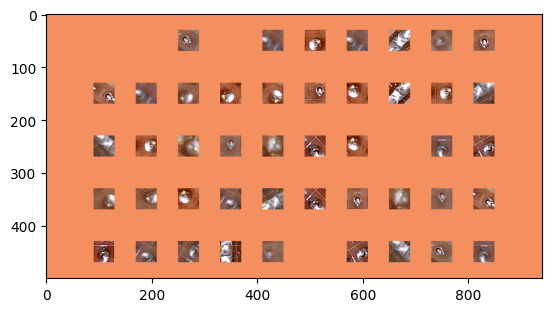

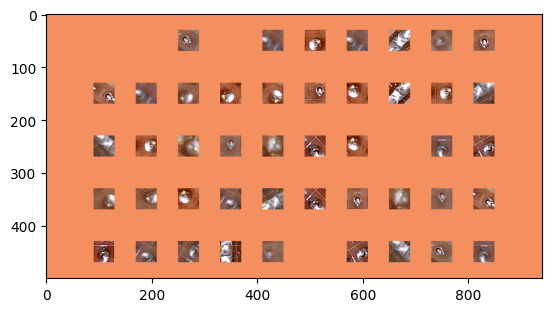

In [32]:
img = cv2.imread(IMAGE_PATH)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

image_np = np.array(img)

input_tensor = tf.convert_to_tensor(np.expand_dims(image_np, 0), dtype=tf.float32)
detections = detect_fn(input_tensor)

num_detections = int(detections.pop('num_detections'))
detections = {key: value[0, :num_detections].numpy()
              for key, value in detections.items()}
detections['num_detections'] = num_detections

# detection_classes should be ints.
detections['detection_classes'] = detections['detection_classes'].astype(np.int64)

label_id_offset = 1
image_np_with_detections = image_np.copy()
viz_utils.visualize_boxes_and_labels_on_image_array(
            image_np_with_detections,
            detections['detection_boxes'],
            detections['detection_classes']+label_id_offset,
            detections['detection_scores'],
            category_index,
            use_normalized_coordinates=True,
            max_boxes_to_draw=100,
            min_score_thresh=.50,
            agnostic_mode=False)


plt.imshow(cv2.cvtColor(image_np_with_detections, cv2.COLOR_BGR2RGB))
plt.show()


> ## 11. Detectando da Camera

In [17]:
cap = cv2.VideoCapture(0)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

while cap.isOpened(): 
    ret, frame = cap.read()
    image_np = np.array(frame)
    
    input_tensor = tf.convert_to_tensor(np.expand_dims(image_np, 0), dtype=tf.float32)
    detections = detect_fn(input_tensor)
    
    num_detections = int(detections.pop('num_detections'))
    detections = {key: value[0, :num_detections].numpy()
                  for key, value in detections.items()}
    detections['num_detections'] = num_detections

    # detection_classes should be ints.
    detections['detection_classes'] = detections['detection_classes'].astype(np.int64)

    label_id_offset = 1
    image_np_with_detections = image_np.copy()

    viz_utils.visualize_boxes_and_labels_on_image_array(
                image_np_with_detections,
                detections['detection_boxes'],
                detections['detection_classes']+label_id_offset,
                detections['detection_scores'],
                category_index,
                use_normalized_coordinates=True,
                max_boxes_to_draw=5,
                min_score_thresh=.8,
                agnostic_mode=False)

    cv2.imshow('object detection',  cv2.resize(image_np_with_detections, (800, 600)))
    
    if cv2.waitKey(10) & 0xFF == ord('q'):
        cap.release()
        cv2.destroyAllWindows()
        break